In [23]:
from pathlib import Path

import numpy as np
import pandas as pd


dataset_path = Path(
    r"C:\Users\Pranav\Desktop\expected-credit-loss-calculator\data\raw\synthetic_ecl_dataset.xlsx"
)

loan_data = pd.read_excel(
    dataset_path,
    sheet_name="Loan_Data",
)

scenario_data = pd.read_excel(
    dataset_path,
    sheet_name="Scenarios",
)

print("Loan data shape:", loan_data.shape)
print("Scenario data shape:", scenario_data.shape)

display(loan_data.head())
display(scenario_data)

Loan data shape: (1000, 20)
Scenario data shape: (3, 5)


,loan_id,reporting_date,origination_date,currency,loan_type,original_loan_amount,outstanding_balance,annual_interest_rate,effective_annual_interest_rate,original_term_months,loan_age_months,remaining_term_months,scheduled_monthly_payment,days_past_due,original_probability_of_default,current_probability_of_default,loss_given_default,credit_impaired,qualitative_risk_flag,credit_risk_stage
0,LOAN0001,2026-09-30,2024-12-31,EUR,unsecured_personal,6100,3703.64,0.092027,0.096010,48,21,27,152.39,0,0.022785,0.015211,0.483213,False,False,1
1,LOAN0002,2026-09-30,2025-07-31,EUR,unsecured_personal,28000,12464.62,0.117193,0.123697,24,14,10,1314.39,0,0.039282,0.052657,0.501761,False,False,1
2,LOAN0003,2026-09-30,2025-03-31,EUR,unsecured_personal,9000,7189.77,0.091792,0.095754,72,18,54,163.03,0,0.012013,0.011276,0.466834,False,False,1
3,LOAN0004,2026-09-30,2023-03-31,EUR,unsecured_personal,13400,4847.10,0.081789,0.084926,60,42,18,272.85,15,0.006900,0.007022,0.509429,False,False,1
4,LOAN0005,2026-09-30,2022-07-31,EUR,unsecured_personal,16100,6093.45,0.088493,0.092172,72,50,22,289.01,8,0.004747,0.005005,0.390770,False,False,1


,scenario,scenario_weight,annual_pd_multiplier,lgd_multiplier,description
0,Base,0.6,1.00,1.00,Use the assumed PD and LGD inputs.
1,Upside,0.2,0.75,0.90,Assume lower default probabilities and lower l...
2,Downside,0.2,1.50,1.15,Assume higher default probabilities and higher...


In [24]:
from src.ecl_calculator import calculate_portfolio_ecl

ModuleNotFoundError: No module named 'src'

In [ ]:
print("Loan data shape:", loan_data.shape)
print("Scenario data shape:", scenario_data.shape)

print("\nMissing values in loan data:")
display(loan_data.isna().sum().to_frame("missing_values"))

print("\nDuplicate loan rows:", loan_data.duplicated().sum())

print("\nNumeric summary:")
display(loan_data.describe().T)

print("\nScenario assumptions:")
display(scenario_data)

Loan data shape: (1000, 20)
Scenario data shape: (3, 5)

Missing values in loan data:


,missing_values
loan_id,0
reporting_date,0
origination_date,0
currency,0
loan_type,0
original_loan_amount,0
outstanding_balance,0
annual_interest_rate,0
effective_annual_interest_rate,0
original_term_months,0



Duplicate loan rows: 0

Numeric summary:


,count,mean,min,25%,50%,75%,max,std
reporting_date,1000,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,NaN
origination_date,1000,2024-08-24 15:38:52.800000,2021-03-31 00:00:00,2023-12-31 00:00:00,2024-12-31 00:00:00,2025-07-31 00:00:00,2025-12-31 00:00:00,NaN
original_loan_amount,1000.0,22168.8,3000.0,11800.0,18400.0,28425.0,65000.0,14231.550991
outstanding_balance,1000.0,11325.66389,387.61,5143.2725,8656.535,14573.65,60858.78,8964.898207
annual_interest_rate,1000.0,0.091049,0.063924,0.079258,0.08826,0.100441,0.142506,0.016004
effective_annual_interest_rate,1000.0,0.095074,0.065831,0.082202,0.09192,0.105197,0.152192,0.017487
original_term_months,1000.0,47.556,24.0,36.0,48.0,60.0,72.0,16.968996
loan_age_months,1000.0,25.184,9.0,14.0,21.0,33.0,66.0,13.576688
remaining_term_months,1000.0,22.372,6.0,11.0,18.0,32.0,63.0,14.141768
scheduled_monthly_payment,1000.0,635.53503,51.21,292.7175,492.275,820.52,3063.97,489.824554



Scenario assumptions:


,scenario,scenario_weight,annual_pd_multiplier,lgd_multiplier,description
0,Base,0.6,1.00,1.00,Use the assumed PD and LGD inputs.
1,Upside,0.2,0.75,0.90,Assume lower default probabilities and lower l...
2,Downside,0.2,1.50,1.15,Assume higher default probabilities and higher...


In [ ]:
stage_3_condition = (
    loan_data["credit_impaired"]
    | (loan_data["days_past_due"] >= 90)
)

pd_increase = (
    loan_data["current_probability_of_default"]
    - loan_data["original_probability_of_default"]
)

stage_2_condition = (
    (loan_data["days_past_due"] >= 30)
    | loan_data["qualitative_risk_flag"]
    | (
        (
            loan_data["current_probability_of_default"]
            >= 2 * loan_data["original_probability_of_default"]
        )
        & (pd_increase >= 0.01)
    )
)

loan_data["calculated_credit_risk_stage"] = np.select(
    [stage_3_condition, stage_2_condition],
    [3, 2],
    default=1,
)

loan_data["calculated_credit_risk_stage"] = (
    loan_data["calculated_credit_risk_stage"].astype(int)
)

loan_data[
    [
        "loan_id",
        "credit_risk_stage",
        "calculated_credit_risk_stage",
    ]
].head()

,loan_id,credit_risk_stage,calculated_credit_risk_stage
0,LOAN0001,1,1
1,LOAN0002,1,1
2,LOAN0003,1,1
3,LOAN0004,1,1
4,LOAN0005,1,1


In [ ]:
stage_comparison = pd.crosstab(
    loan_data["credit_risk_stage"],
    loan_data["calculated_credit_risk_stage"],
    rownames=["Reference stage"],
    colnames=["Calculated stage"],
)

matching_stage_count = (
    loan_data["credit_risk_stage"]
    == loan_data["calculated_credit_risk_stage"]
).sum()

print(f"Matching stage labels: {matching_stage_count} of {len(loan_data)}")
display(stage_comparison)

Matching stage labels: 1000 of 1000


Calculated stage,1,2,3
Reference stage,,,
1,750,0,0
2,0,210,0
3,0,0,40


In [ ]:
stage_summary = (
    loan_data.groupby("calculated_credit_risk_stage")
    .agg(
        loan_count=("loan_id", "count"),
        total_exposure=("outstanding_balance", "sum"),
        average_current_pd=("current_probability_of_default", "mean"),
        average_lgd=("loss_given_default", "mean"),
    )
    .round(4)
)

display(stage_summary)

,loan_count,total_exposure,average_current_pd,average_lgd
calculated_credit_risk_stage,,,,
1,750,8375461.07,0.0194,0.4757
2,210,2337198.01,0.1585,0.5343
3,40,613004.81,1.0000,0.5960


In [ ]:
def calculate_loan_ecl(loan_record, scenario_record):
    annual_pd = min(
        loan_record["current_probability_of_default"]
        * scenario_record["annual_pd_multiplier"],
        1.0,
    )

    if loan_record["credit_impaired"]:
        annual_pd = 1.0

    monthly_pd = 1 - (1 - annual_pd) ** (1 / 12)

    adjusted_lgd = min(
        loan_record["loss_given_default"]
        * scenario_record["lgd_multiplier"],
        1.0,
    )

    if loan_record["credit_impaired"]:
        return (
            loan_record["outstanding_balance"]
            * adjusted_lgd
        )

    credit_risk_stage = loan_record["calculated_credit_risk_stage"]
    remaining_term_months = int(loan_record["remaining_term_months"])

    if credit_risk_stage == 1:
        calculation_horizon_months = min(12, remaining_term_months)
    else:
        calculation_horizon_months = remaining_term_months

    balance = loan_record["outstanding_balance"]
    monthly_payment = loan_record["scheduled_monthly_payment"]
    monthly_interest_rate = loan_record["annual_interest_rate"] / 12

    effective_annual_rate = loan_record[
        "effective_annual_interest_rate"
    ]
    monthly_discount_rate = (
        (1 + effective_annual_rate) ** (1 / 12)
    ) - 1

    survival_probability = 1.0
    expected_credit_loss = 0.0

    for month_number in range(1, calculation_horizon_months + 1):
        exposure_at_default = balance

        marginal_default_probability = (
            survival_probability * monthly_pd
        )

        discount_factor = (
            1 + monthly_discount_rate
        ) ** (-month_number)

        expected_credit_loss += (
            exposure_at_default
            * adjusted_lgd
            * marginal_default_probability
            * discount_factor
        )

        survival_probability *= 1 - monthly_pd

        interest_payment = balance * monthly_interest_rate
        principal_payment = max(
            monthly_payment - interest_payment,
            0.0,
        )

        balance = max(balance - principal_payment, 0.0)

        if balance == 0:
            break

    return expected_credit_loss

In [ ]:
ecl_results = []

for loan_record in loan_data.to_dict("records"):
    for scenario_record in scenario_data.to_dict("records"):
        loan_ecl = calculate_loan_ecl(
            loan_record,
            scenario_record,
        )

        ecl_results.append(
            {
                "loan_id": loan_record["loan_id"],
                "credit_risk_stage": (
                    loan_record["calculated_credit_risk_stage"]
                ),
                "scenario": scenario_record["scenario"],
                "scenario_weight": scenario_record["scenario_weight"],
                "expected_credit_loss": loan_ecl,
            }
        )

ecl_results = pd.DataFrame(ecl_results)

display(ecl_results.head())
print("Number of loan-scenario calculations:", len(ecl_results))

,loan_id,credit_risk_stage,scenario,scenario_weight,expected_credit_loss
0,LOAN0001,1,Base,0.6,21.115537
1,LOAN0001,1,Upside,0.2,14.250244
2,LOAN0001,1,Downside,0.2,36.438405
3,LOAN0002,1,Base,0.6,148.984580
4,LOAN0002,1,Upside,0.2,100.275201


Number of loan-scenario calculations: 3000


In [ ]:
ecl_results["weighted_expected_credit_loss"] = (
    ecl_results["expected_credit_loss"]
    * ecl_results["scenario_weight"]
)

portfolio_ecl = (
    ecl_results.groupby("scenario")
    .agg(
        scenario_weight=("scenario_weight", "first"),
        scenario_ecl=("expected_credit_loss", "sum"),
        weighted_ecl=("weighted_expected_credit_loss", "sum"),
    )
)

total_expected_credit_loss = portfolio_ecl[
    "weighted_ecl"
].sum()

display(portfolio_ecl.round(2))

print(
    "Total probability-weighted portfolio ECL:",
    round(total_expected_credit_loss, 2),
    "EUR",
)

,scenario_weight,scenario_ecl,weighted_ecl
scenario,,,
Base,0.6,640805.32,384483.19
Downside,0.2,874065.57,174813.11
Upside,0.2,519223.69,103844.74


Total probability-weighted portfolio ECL: 663141.04 EUR


In [ ]:
loan_level_ecl = (
    ecl_results.groupby(
        ["loan_id", "credit_risk_stage"],
        as_index=False,
    )
    .agg(
        weighted_ecl=(
            "weighted_expected_credit_loss",
            "sum",
        )
    )
)

stage_ecl_summary = (
    loan_level_ecl.groupby("credit_risk_stage")
    .agg(
        loan_count=("loan_id", "count"),
        total_weighted_ecl=("weighted_ecl", "sum"),
        average_weighted_ecl_per_loan=("weighted_ecl", "mean"),
    )
    .round(2)
)

display(stage_ecl_summary)

,loan_count,total_weighted_ecl,average_weighted_ecl_per_loan
credit_risk_stage,,,
1,750,60561.98,80.75
2,210,238442.40,1135.44
3,40,364136.67,9103.42


In [ ]:
scenario_summary = (
    ecl_results.groupby("scenario")
    .agg(
        scenario_weight=("scenario_weight", "first"),
        total_scenario_ecl=("expected_credit_loss", "sum"),
        weighted_ecl=("weighted_expected_credit_loss", "sum"),
    )
    .reindex(["Upside", "Base", "Downside"])
    .round(2)
)

display(scenario_summary)

,scenario_weight,total_scenario_ecl,weighted_ecl
scenario,,,
Upside,0.2,519223.69,103844.74
Base,0.6,640805.32,384483.19
Downside,0.2,874065.57,174813.11


In [ ]:
total_portfolio_exposure = loan_data["outstanding_balance"].sum()

ecl_coverage_ratio_percent = (
    total_expected_credit_loss
    / total_portfolio_exposure
    * 100
)

stage_ecl_summary["share_of_total_ecl_percent"] = (
    stage_ecl_summary["total_weighted_ecl"]
    / total_expected_credit_loss
    * 100
)

print(f"Total portfolio exposure: €{total_portfolio_exposure:,.2f}")
print(f"Probability-weighted ECL: €{total_expected_credit_loss:,.2f}")
print(f"ECL coverage ratio: {ecl_coverage_ratio_percent:.2f}%")

display(stage_ecl_summary.round(2))

Total portfolio exposure: €11,325,663.89
Probability-weighted ECL: €663,141.04
ECL coverage ratio: 5.86%


,loan_count,total_weighted_ecl,average_weighted_ecl_per_loan,share_of_total_ecl_percent
credit_risk_stage,,,,
1,750,60561.98,80.75,9.13
2,210,238442.40,1135.44,35.96
3,40,364136.67,9103.42,54.91


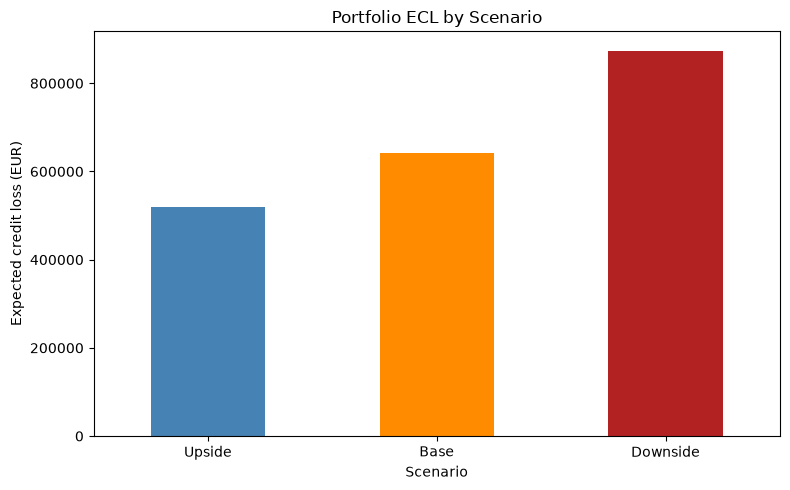

In [ ]:
import matplotlib.pyplot as plt


project_root = dataset_path.parents[2]
outputs_folder = project_root / "outputs"
outputs_folder.mkdir(parents=True, exist_ok=True)

scenario_ecl = scenario_summary["total_scenario_ecl"]

scenario_ecl.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "darkorange", "firebrick"],
)

plt.title("Portfolio ECL by Scenario")
plt.xlabel("Scenario")
plt.ylabel("Expected credit loss (EUR)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    outputs_folder / "ecl_by_scenario.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

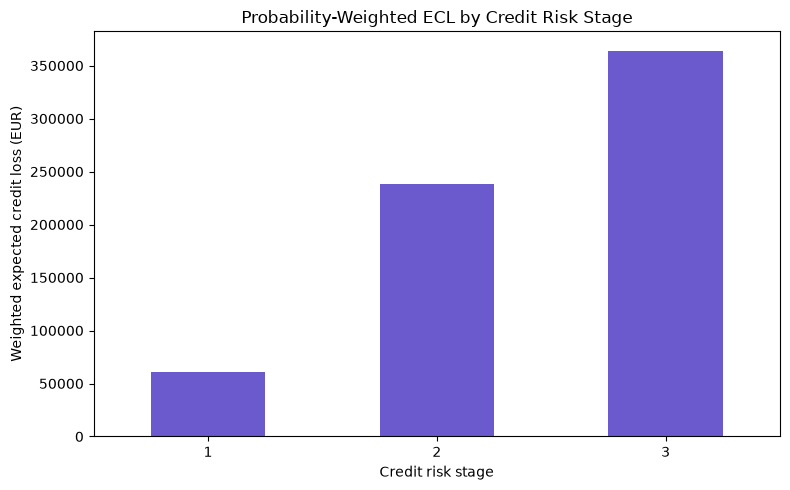

In [ ]:
stage_ecl = stage_ecl_summary["total_weighted_ecl"]

stage_ecl.plot(
    kind="bar",
    figsize=(8, 5),
    color="slateblue",
)

plt.title("Probability-Weighted ECL by Credit Risk Stage")
plt.xlabel("Credit risk stage")
plt.ylabel("Weighted expected credit loss (EUR)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    outputs_folder / "ecl_by_stage.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
assert np.isclose(
    scenario_data["scenario_weight"].sum(),
    1.0,
), "Scenario weights must sum to 1."

assert (
    loan_data["credit_risk_stage"]
    == loan_data["calculated_credit_risk_stage"]
).all(), "Calculated stages do not match the reference stages."

assert np.isfinite(
    ecl_results["expected_credit_loss"]
).all(), "ECL results contain missing or infinite values."

assert (
    ecl_results["expected_credit_loss"] >= 0
).all(), "ECL results cannot be negative."

assert (
    scenario_summary.loc["Upside", "total_scenario_ecl"]
    <= scenario_summary.loc["Base", "total_scenario_ecl"]
    <= scenario_summary.loc["Downside", "total_scenario_ecl"]
), "Scenario ECL results are not in the expected order."

np.testing.assert_allclose(
    stage_ecl_summary["total_weighted_ecl"].sum(),
    total_expected_credit_loss,
)

print("All model checks passed.")

All model checks passed.


In [ ]:
print(f"Total portfolio exposure: €{total_portfolio_exposure:,.2f}")
print(f"Probability-weighted ECL: €{total_expected_credit_loss:,.2f}")
print(f"ECL coverage ratio: {ecl_coverage_ratio_percent:.2f}%")

print("\nECL by stage:")
display(stage_ecl_summary.round(2))

print("\nECL by scenario:")
display(scenario_summary.round(2))

Total portfolio exposure: €11,325,663.89
Probability-weighted ECL: €663,141.04
ECL coverage ratio: 5.86%

ECL by stage:


,loan_count,total_weighted_ecl,average_weighted_ecl_per_loan,share_of_total_ecl_percent
credit_risk_stage,,,,
1,750,60561.98,80.75,9.13
2,210,238442.40,1135.44,35.96
3,40,364136.67,9103.42,54.91



ECL by scenario:


,scenario_weight,total_scenario_ecl,weighted_ecl
scenario,,,
Upside,0.2,519223.69,103844.74
Base,0.6,640805.32,384483.19
Downside,0.2,874065.57,174813.11


In [ ]:
loan_level_ecl.to_excel(
    outputs_folder / "loan_level_ecl.xlsx",
    index=False,
)

with pd.ExcelWriter(
    outputs_folder / "ecl_summary.xlsx",
    engine="openpyxl",
) as excel_writer:
    scenario_summary.to_excel(
        excel_writer,
        sheet_name="Scenario Summary",
    )

    stage_ecl_summary.to_excel(
        excel_writer,
        sheet_name="Stage Summary",
    )

    ecl_results.to_excel(
        excel_writer,
        sheet_name="Loan Scenario Results",
        index=False,
    )

print("Results saved in:", outputs_folder)

Results saved in: C:\Users\Pranav\Desktop\expected-credit-loss-calculator\outputs
